# CURVEPLOTS — reusable `zedstat` curve and CI API

Paper-specific configuration and data paths stay here. All score-level ROC/PRC/LR calculations, log-ratio CIs, fixed-specificity bootstrap, plotting, and LaTeX rendering reside in `zedstat.curveplots` (with underlying `zedstat.pr_ci` and `zedstat.ci_logratio`).

Inputs: `PAPER_DATA_MARKETSCAN/` and `PAPER_DATA_UKHC_50TRAINING/`. Outputs unchanged: 9 PDF + 9 PNG panels, 3 LaTeX tables, and one UKHC pointwise bootstrap CSV. Display smoothing is cosmetic, not a simultaneous CI guarantee.

Run with a `zedstat` installation containing `zedstat.curveplots`; see repository installation instructions.

In [1]:
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from zedstat.curveplots import (
    score_curve_bundle, plot_curve_panel, fixed_specificity_bootstrap,
    performance_table_latex,
)

print('zedstat version:', version('zedstat'))

# Analysis-specific input/output paths and output naming.
COHORT_FOLDERS = {
    'MarketScan': Path('PAPER_DATA_MARKETSCAN'),
    'UKHC': Path('PAPER_DATA_UKHC_50TRAINING'),
}
OUTPUT_DIR = Path('PUBLICATION_FILES')
PANEL_DIR = OUTPUT_DIR / 'CURVEPLOTS'
PANEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

HORIZONS = ('1M', '6M', '1Y')
TARGET_LABELS = {
    'Oxygen_Dependence': 'Oxy. Dep.',
    'Pulmonary_Hypertension': 'Pulm. Hypert.',
    'ARDS': 'ARDS',
}
EVENT_LABELS = {
    'Pulmonary_Hypertension': 'Pulmonary Hypertension',
    'Oxygen_Dependence': 'Oxygen Dependence',
    'ARDS': 'ARDS',
}
TARGETS = tuple(TARGET_LABELS)
COHORTS = tuple(COHORT_FOLDERS)
COLORS = {'Oxygen_Dependence':'#0000FF', 'Pulmonary_Hypertension':'#FF0000', 'ARDS':'#27D655'}
COHORT_STYLES = {
    'MarketScan': {'linestyle': '-', 'alpha': 0.25},
    'UKHC': {'linestyle': (0, (4, 2)), 'alpha': 0.125},
}
SUBSTITUTE_UKHC_PREVALENCE = False
OPERATING_SPECIFICITY = 0.95
BOOT_DRAWS, BOOT_SEED, CI_LEVEL = 5000, 20261112, 0.95

# Publication appearance (all estimator options are explicit in the call below).
mpl.rcParams.update({
    'font.family':'sans-serif', 'font.sans-serif':['Arial','Liberation Sans','DejaVu Sans'],
    'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8,
    'text.usetex':False, 'pdf.fonttype':42, 'ps.fonttype':42,
    'axes.unicode_minus':True, 'savefig.transparent':False,
})

zedstat version: 0.2.8


## Load predictions and calculate all three curve families

In [2]:
PREDICTIONS, BUNDLES = {}, {}
for horizon in HORIZONS:
    for cohort, folder in COHORT_FOLDERS.items():
        for target in TARGETS:
            directory = f"curves{horizon}_{cohort.upper()}"
            path = folder / directory / f'PREDS_{target}.csv'
            if not path.is_file():
                raise FileNotFoundError(path)
            PREDICTIONS[horizon, cohort, target] = pd.read_csv(path)

for horizon in HORIZONS:
    for cohort in COHORTS:
        for target in TARGETS:
            df = PREDICTIONS[horizon, cohort, target]
            reference = (PREDICTIONS[horizon, 'MarketScan', target]
                         if cohort == 'UKHC' and SUBSTITUTE_UKHC_PREVALENCE else df)
            BUNDLES[horizon, cohort, target] = score_curve_bundle(
                df,
                prevalence=float(reference['target'].mean()),
                prevalence_sample_size=len(reference),
                score_col='predicted_risk', label_col='target',
                roc_alpha=0.05, roc_fpr_floor=0.001,
                roc_smoothing_step=0.01, roc_usample_precision=3,
                roc_min_expected_flags=10.0, roc_min_expected_fp=5.0,
                roc_min_expected_tn=5.0, roc_min_lrplus=1.001,
                pr_min_tp=10, pr_min_fp=5, pr_min_flags=20,
                pr_max_points=1000, pr_display_sigma=1.5,
                lr_min_cell_count=10, lr_fpr_min=0.005, lr_fpr_max=0.95,
                lr_min_plus=1.001, lr_display_sigma=4.0,
                confidence=CI_LEVEL,
            )
print('Computed', len(BUNDLES), 'cohort/horizon/target curve bundles')

Computed 18 cohort/horizon/target curve bundles


## Save the nine PDF and PNG panels

In [3]:
for horizon in HORIZONS:
    bundles = {(cohort, target): BUNDLES[horizon, cohort, target]
               for cohort in COHORTS for target in TARGETS}
    for view in ('ROC', 'PPV', 'LR'):
        plot_curve_panel(
            bundles, view, targets=TARGETS, cohorts=COHORTS,
            colors=COLORS, cohort_styles=COHORT_STYLES, target_labels=TARGET_LABELS,
            output_stem=PANEL_DIR / f'CURVEPLOT_{horizon}_ILD_{view}',
            panel_side_in=1.85, margins_in=(0.52,0.45,0.18,0.15),
            linewidth=1.2, png_dpi=400, pr_use_display=True,
            lr_use_display=True, lr_y_log_axis=False,
            roc_legend_position=(0.24,0.02),
        )
print('Saved nine PDFs and nine PNGs:', PANEL_DIR)

Saved nine PDFs and nine PNGs: PUBLICATION_FILES/CURVEPLOTS


## UKHC operating-point bootstrap and manuscript tables

In [4]:
BOOTSTRAP, records = {}, []
for horizon in HORIZONS:
    for index, target in enumerate(TARGETS):
        df = PREDICTIONS[horizon, 'UKHC', target]
        external_p = (float(PREDICTIONS[horizon, 'MarketScan', target]['target'].mean())
                      if SUBSTITUTE_UKHC_PREVALENCE else None)
        estimates, provenance = fixed_specificity_bootstrap(
            df, specificity=OPERATING_SPECIFICITY,
            n_boot=BOOT_DRAWS, seed=BOOT_SEED + 100*HORIZONS.index(horizon) + index,
            prevalence=external_p, confidence=CI_LEVEL,
            score_col='predicted_risk', label_col='target',
        )
        BOOTSTRAP[horizon, 'UKHC', target] = estimates
        for metric, (value, lower, upper) in estimates.items():
            records.append({'horizon':horizon, 'dataset':'UKHC', 'outcome':target,
                            'metric':metric, 'estimate':value, 'ci_lower':lower,
                            'ci_upper':upper, 'ci_halfwidth':(upper-lower)/2, **provenance})
UKHC_FINAL_METRICS = pd.DataFrame(records)
UKHC_FINAL_METRICS.to_csv(OUTPUT_DIR/'UKHC_95spec_final_bootstrap_CIs.csv', index=False)
display(UKHC_FINAL_METRICS[['horizon','outcome','metric','estimate','ci_lower','ci_upper']].round(4))

HORIZON_INFO = {
    '1M': ('1 month', 'table_perf_MOVING'),
    '6M': ('6 months', 'table_perf_ILD_MOVING_6M'),
    '1Y': ('1 year', 'table_perf_ILD_MOVING_1Y'),
}
FOOTNOTES = (
    r'$^\bigstar$ LR$+$: positive likelihood ratio, LR$-$: negative likelihood ratio, PPV: positive predictive value, NPV: negative predictive value.',
    r'UKHC operating metrics are evaluated at FPR = 0.05 (95\% specificity) with 5,000 stratified score-level ROC bootstrap replicates; percentile 95\% intervals include estimated prevalence uncertainty for PPV and NPV.',
    "MarketScan operating-point intervals and AUC intervals are from zedstat's analytical calculations; both datasets use the zedstat AUC estimates.",
    r'The $\pm$ terms denote half the corresponding 95\% confidence-interval widths. Exact UKHC percentile endpoints are provided in the companion CSV.',
)
for horizon, (description, label) in HORIZON_INFO.items():
    caption = (f'Out-of-sample prediction performance for natural history events '
               f'in the MarketScan and UKHC ILD cohorts at a horizon of {description}'
               r'$^\bigstar$')
    bundles = {(cohort, target): BUNDLES[horizon, cohort, target]
               for cohort in COHORTS for target in TARGETS}
    bootstrap = {('UKHC', target): BOOTSTRAP[horizon, 'UKHC', target]
                 for target in TARGETS}
    tex = performance_table_latex(
        bundles, target_labels=EVENT_LABELS, cohorts=COHORTS,
        specificity=OPERATING_SPECIFICITY, caption=caption, label=label,
        bootstrap_estimates=bootstrap, footnotes=FOOTNOTES,
    )
    path = OUTPUT_DIR / f'PERFORMANCE_TABLE_{horizon}.tex'
    path.write_text(tex, encoding='utf-8')
    print('Saved:', path)

,horizon,outcome,metric,estimate,ci_lower,ci_upper
0,1M,Oxygen_Dependence,tpr,0.3509,0.2500,0.4365
1,1M,Oxygen_Dependence,ppv,0.7880,0.7196,0.8271
2,1M,Oxygen_Dependence,npv,0.7343,0.6951,0.7676
3,1M,Oxygen_Dependence,LR+,7.0175,5.0000,8.7292
4,1M,Oxygen_Dependence,LR-,0.6833,0.5932,0.7895
5,1M,Pulmonary_Hypertension,tpr,0.3539,0.2532,0.4188
6,1M,Pulmonary_Hypertension,ppv,0.6907,0.6109,0.7342
7,1M,Pulmonary_Hypertension,npv,0.8233,0.7941,0.8468
8,1M,Pulmonary_Hypertension,LR+,7.0779,5.0649,8.3766
9,1M,Pulmonary_Hypertension,LR-,0.6801,0.6118,0.7861


Saved: PUBLICATION_FILES/PERFORMANCE_TABLE_1M.tex
Saved: PUBLICATION_FILES/PERFORMANCE_TABLE_6M.tex
Saved: PUBLICATION_FILES/PERFORMANCE_TABLE_1Y.tex


## Optional figure preview

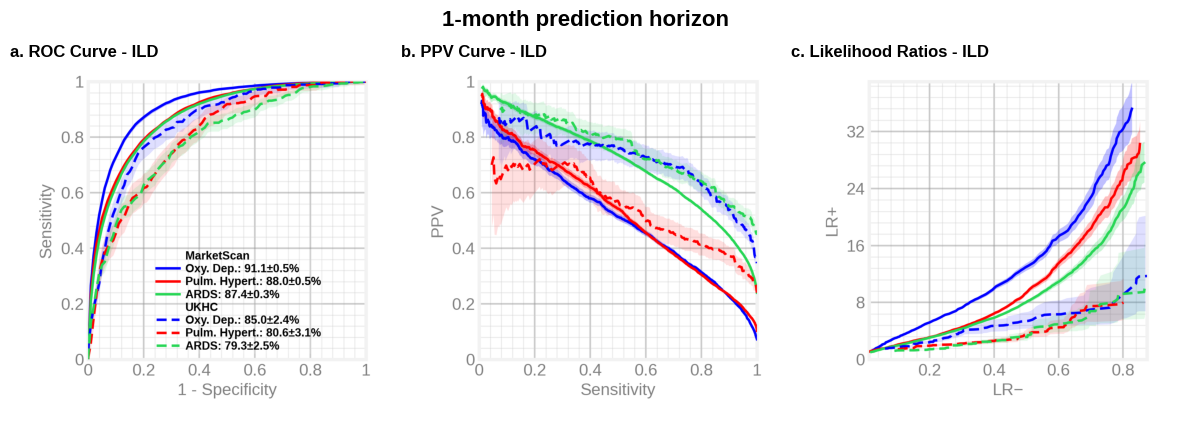

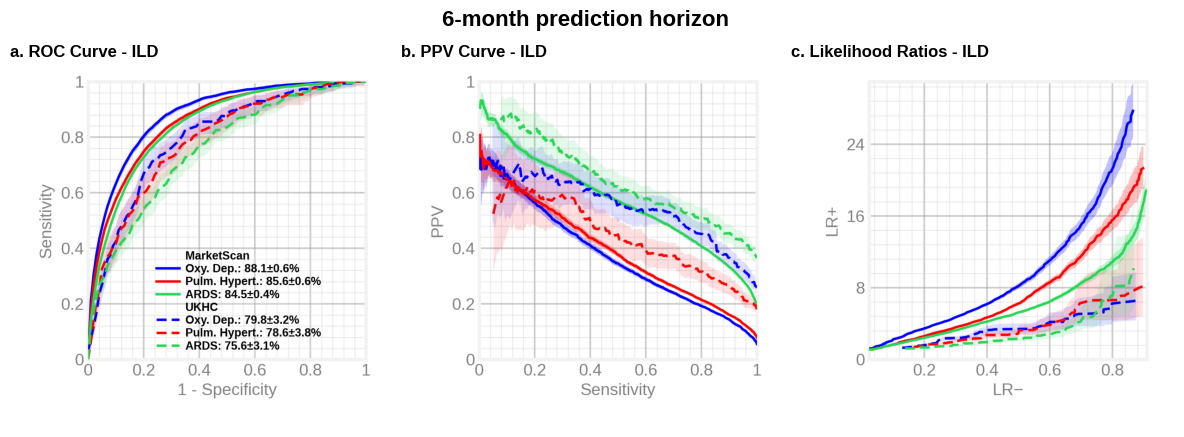

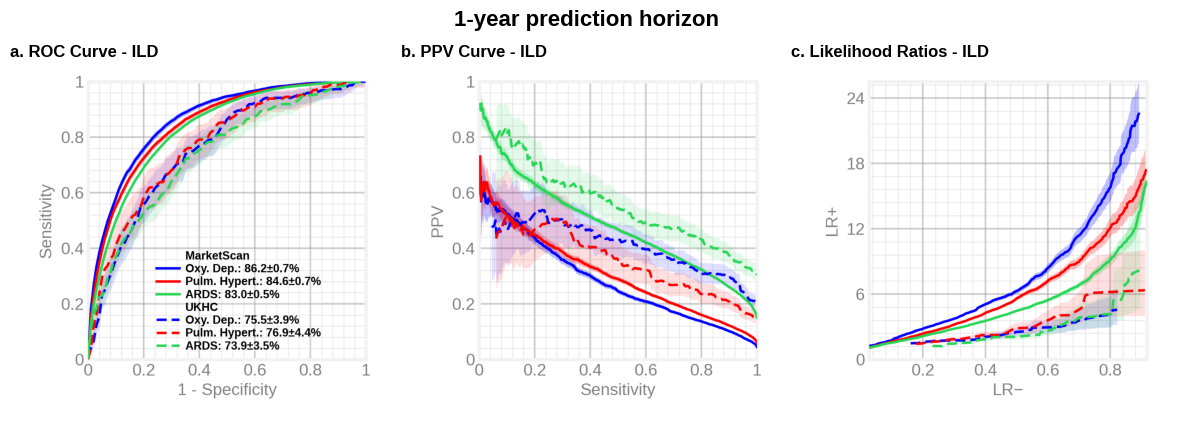

In [5]:
# Manuscript display preview (does not recompute statistics).
HORIZON_TITLES = {
    '1M':'1-month prediction horizon',
    '6M':'6-month prediction horizon',
    '1Y':'1-year prediction horizon',
}
PANEL_TITLES = {'ROC':'ROC Curve','PPV':'PPV Curve','LR':'Likelihood Ratios'}
for horizon, title in HORIZON_TITLES.items():
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
    fig.suptitle(title, fontsize=16, fontweight='semibold', y=.99)
    for j, (ax, view) in enumerate(zip(axes, ('ROC','PPV','LR'))):
        ax.imshow(plt.imread(PANEL_DIR/f'CURVEPLOT_{horizon}_ILD_{view}.png'))
        ax.axis('off')
        ax.set_title(f'{chr(ord("a")+j)}. {PANEL_TITLES[view]} - ILD',
                     loc='left', fontsize=12, fontweight='semibold', pad=2)
    fig.subplots_adjust(left=.02, right=.99, bottom=.01, top=.93, wspace=.02)
    plt.show()
    plt.close(fig)